# Gaussian-process correction re-scored on the official metric (not built)

**The question:** the offset GP (`docs/gaussian_process.md`) gained 1.6% over the old linear model
on the per-run TIMSE. Does a GP correction help the re-tuned linear model on the official metric?

**The run** (`python -m training.gaussian_process_folds`, `--metric official`): the submitted linear
model (official loss weights, blend 0.25) is refitted on each yearly fold. One GP on each run's
weighted mean offset (observed - linear) is conditioned on 4,000 random fit runs, for input sets A
(the linear model's regressors) and H (the hybrid's 30), lengthscale 1/3/10/30 and noise/signal
1/10/100. Scored with the official S_final against the official truth.

**Decision rule** (set before running): more than 1% better than the linear model, winning at least
4 of 6 folds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import gaussian_process_folds as gpf

df = pd.read_csv(gpf.EXPERIMENTS / "gaussian_process_official.csv").set_index("fold")
grid = [c for c in df.columns if c.startswith("offset") and "|" not in c]
ratio = df[grid].div(df["linear"], axis=0)
summary = pd.DataFrame({
    "S_final": df[grid].mean(),
    "vs linear %": 100 * (np.exp(np.log(ratio).mean()) - 1),
    "folds won": (ratio < 1).sum(),
    "mean correction": [df[f"{c} | mean correction"].mean() for c in grid],
}).sort_values("vs linear %")
print(f"linear: S_final {df['linear'].mean():.2f} km/s; persistence {df['persistence'].mean():.2f}")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(summary)

linear: S_final 88.49 km/s; persistence 110.57


,S_final,vs linear %,folds won,mean correction
offset A ls=3 nr=100,88.348,-0.377,3,-1.992
offset A ls=10 nr=100,88.315,-0.366,3,-0.807
offset H ls=3 nr=100,88.274,-0.340,3,-1.270
offset H ls=3 nr=10,88.354,-0.325,3,-1.651
offset A ls=30 nr=100,88.331,-0.236,5,0.040
offset A ls=10 nr=10,88.600,-0.208,2,0.394
offset A ls=30 nr=10,88.437,-0.194,3,-0.260
offset A ls=1 nr=100,88.359,-0.158,4,-2.200
offset H ls=1 nr=1,88.380,-0.128,4,-1.421
offset H ls=30 nr=100,88.444,-0.093,4,1.194


## 1. The grid: % vs the linear model, geometric mean over folds

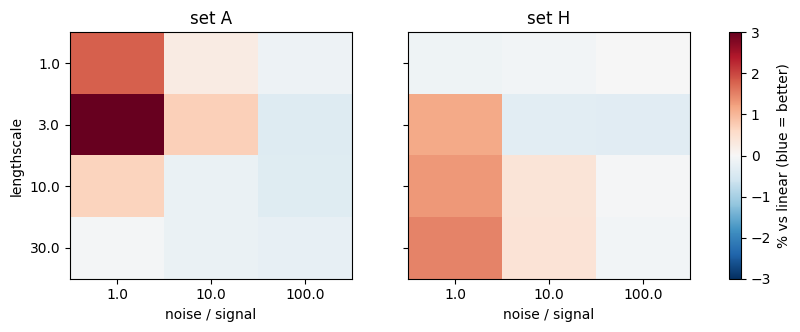

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, s in zip(axes, "AH", strict=True):
    m = pd.DataFrame({nr: [summary.loc[f"offset {s} ls={ls:g} nr={nr:g}", "vs linear %"]
                           for ls in gpf.LENGTHSCALES] for nr in gpf.NOISE_RATIOS},
                     index=gpf.LENGTHSCALES)
    im = ax.imshow(m.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns)
    ax.set_xlabel("noise / signal")
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.set_title(f"set {s}")
axes[0].set_ylabel("lengthscale")
plt.colorbar(im, ax=axes, label="% vs linear (blue = better)")

## 2. By fold: each fold's best setting is a different one

In [3]:
best = ratio.idxmin(axis=1)
per_fold = pd.DataFrame({"linear": df["linear"], "best setting": best,
                         "its gain %": 100 * (ratio.min(axis=1) - 1),
                         "overall best %": 100 * (ratio[summary.index[0]] - 1)})
display(per_fold.round(2))
oracle = 100 * (np.exp(np.log(ratio.min(axis=1)).mean()) - 1)
print(f"best per fold in hindsight (not usable live): {oracle:+.2f}%")

,linear,best setting,its gain %,overall best %
fold,,,,
2019-10,61.01,offset A ls=10 nr=10,-3.50,-2.64
2020-10,69.98,offset A ls=30 nr=1,-2.20,-1.66
2021-10,85.18,offset A ls=30 nr=100,-0.23,0.73
2022-10,91.86,offset H ls=3 nr=10,-0.39,0.80
2023-10,115.87,offset A ls=3 nr=1,-1.75,-0.13
2024-10,107.02,offset H ls=1 nr=1,-0.35,0.69


best per fold in hindsight (not usable live): -1.41%


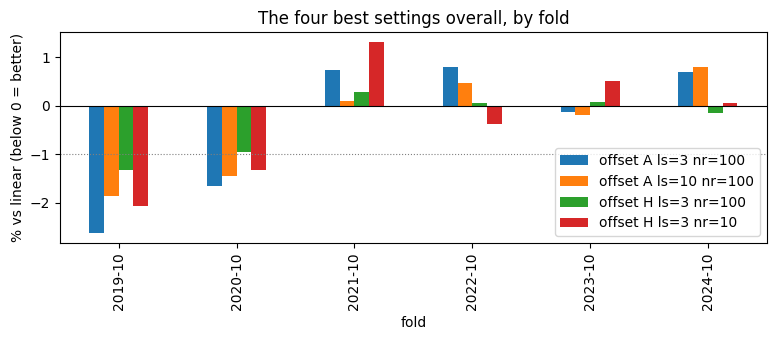

In [4]:
ax = (100 * (ratio[summary.index[:4]] - 1)).plot.bar(figsize=(8, 3.5))
ax.axhline(0, color="k", lw=.8)
ax.axhline(-1, color="grey", ls=":", lw=.8)
ax.set_ylabel("% vs linear (below 0 = better)")
ax.set_title("The four best settings overall, by fold")
plt.tight_layout()

## Findings

1. **Not built.** The best setting (set H, lengthscale 3, noise/signal 100) is 0.34% better in mean
   S_final, and the best by geometric mean is 0.38%; no setting wins more than 3 of 6 folds except
   ones gaining 0.25% or less. The 20 others range up to 3% worse.
2. **The fold winners don't agree.** Each fold's best setting is a different one; even choosing it in
   hindsight, which can't be done live, gains only about 1.4%.
3. **The corrections are tiny,** a mean of -2 to +1 km/s, against the linear model's +22 km/s mean
   bias.
4. **The re-tune absorbed the old gain.** On the old metric the GP corrected the old linear model's
   run-level offset; the official-weights model leaves nothing systematic for a smooth correction.

**Decision:** no change; the submitted linear model stays.